In [32]:
import torch
from tqdm import tqdm
from torch import nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import timm

In [2]:
import kagglehub, shutil
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
shutil.copytree(path, "../data", dirs_exist_ok=True)

'../data'

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [4]:
import os
from pathlib import Path

def walk_through_dir(dir_path):
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories and {len(filenames)} images in {dirpath}.")

image_path = Path("../data")
walk_through_dir(image_path)

There are 2 directories and 0 images in ../data.
There are 4 directories and 0 images in ../data/Testing.
There are 0 directories and 400 images in ../data/Testing/glioma.
There are 0 directories and 400 images in ../data/Testing/meningioma.
There are 0 directories and 400 images in ../data/Testing/notumor.
There are 0 directories and 400 images in ../data/Testing/pituitary.
There are 4 directories and 0 images in ../data/Training.
There are 0 directories and 1400 images in ../data/Training/glioma.
There are 0 directories and 1400 images in ../data/Training/meningioma.
There are 0 directories and 1400 images in ../data/Training/notumor.
There are 0 directories and 1400 images in ../data/Training/pituitary.


In [5]:
train_dir = image_path/'Training'
test_dir = image_path/'Testing'

Random Image Path : ../data/Training/notumor/Tr-no_1147.jpg
Image class : notumor
Image Height : 252
Image width : 200


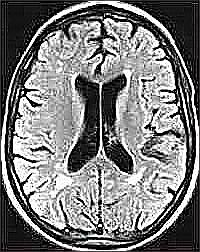

In [6]:
import random
from PIL import Image

random.seed(42)

image_path_list = list(image_path.glob("*/*/*.jpg"))

random_image_path = random.choice(image_path_list)

image_class = random_image_path.parent.stem

img = Image.open(random_image_path)

print(f"Random Image Path : {random_image_path}")
print(f"Image class : {image_class}")
print(f"Image Height : {img.height}")
print(f"Image width : {img.width}")
img

In [7]:
IMG_SIZE = 299  
MEAN = [0.485, 0.456, 0.406] 
STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),  
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),     
    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05),
    ),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),  
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [8]:
train_data = datasets.ImageFolder(root=train_dir,
                                  transform=train_transform,
                                  target_transform=None)
test_data = datasets.ImageFolder(root=test_dir,
                                 transform=test_transform,
                                 target_transform=None)

In [9]:
class_names = train_data.classes
class_names

['glioma', 'meningioma', 'notumor', 'pituitary']

In [10]:
BATCH_SIZE = 32
train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              num_workers=os.cpu_count(),
                              shuffle=True)
test_dataloader = DataLoader(dataset=test_data,
                             batch_size=BATCH_SIZE,
                             num_workers=os.cpu_count(),
                             shuffle=False)
train_dataloader,test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x72c71a927eb0>,
 <torch.utils.data.dataloader.DataLoader at 0x72c71a927370>)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0322802..1.9602616].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.980906..2.2391288].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.980906..1.8905448].


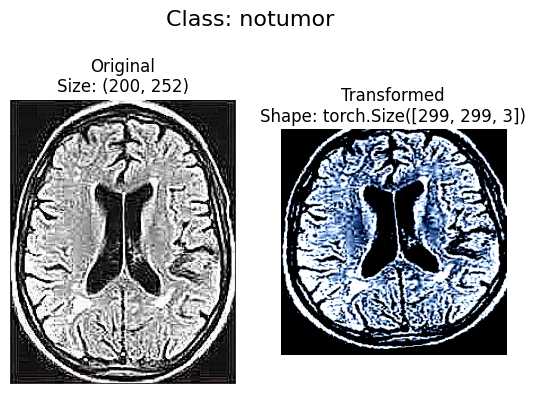

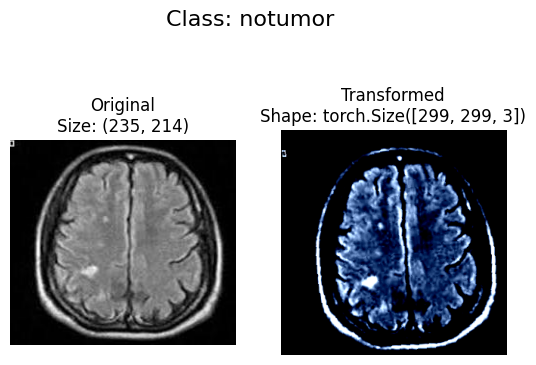

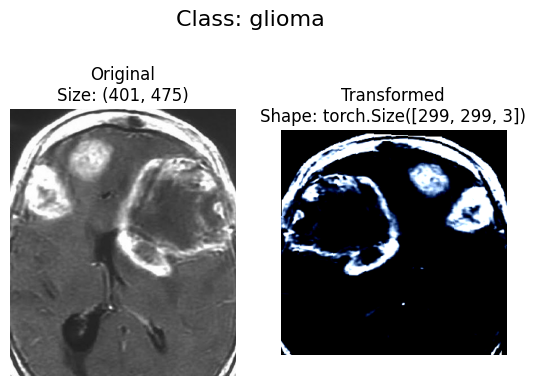

In [11]:
def plot_transformed_images(image_paths,transform,n=3,seed=None):
    if seed:
        random.seed(seed)
    random_image_paths = random.sample(image_paths,k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig,ax = plt.subplots(nrows=1,ncols=2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original\nSize: {f.size}")
            ax[0].axis(False)

            transformed_image = transform(f).permute(1,2,0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed\nShape: {transformed_image.shape}")
            ax[1].axis(False)

            fig.suptitle(f"Class: {image_path.parent.stem}",fontsize=16)

plot_transformed_images(image_paths=image_path_list,transform=train_transform,n=3,seed=42)

In [12]:
from collections import Counter

def class_counts(dataset):
    counts = Counter(dataset.targets)
    return {dataset.classes[i]: n for i, n in sorted(counts.items())}

print("Train:", class_counts(train_data))
print("Test: ", class_counts(test_data))

Train: {'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}
Test:  {'glioma': 400, 'meningioma': 400, 'notumor': 400, 'pituitary': 400}


In [13]:
NUM_CLASSES = len(class_names)

model = timm.create_model("inception_v3.tv_in1k", pretrained=True, num_classes=NUM_CLASSES)

In [14]:
for name, _ in model.named_children():
    print(name)

Conv2d_1a_3x3
Conv2d_2a_3x3
Conv2d_2b_3x3
Pool1
Conv2d_3b_1x1
Conv2d_4a_3x3
Pool2
Mixed_5b
Mixed_5c
Mixed_5d
Mixed_6a
Mixed_6b
Mixed_6c
Mixed_6d
Mixed_6e
Mixed_7a
Mixed_7b
Mixed_7c
global_pool
head_drop
fc


In [15]:
for p in model.parameters():
    p.requires_grad = False

unfreeze = ["Mixed_7a","Mixed_7b", "Mixed_7c", "fc"]   
for name, module in model.named_children():
    if name in unfreeze:
        for p in module.parameters():
            p.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable:,} / {total:,}")


Trainable: 12,827,908 / 21,793,764


In [16]:
backbone_params = [p for n, p in model.named_parameters()
                   if p.requires_grad and not n.startswith("fc")]
head_params = [p for n, p in model.named_parameters()
               if p.requires_grad and n.startswith("fc")]

optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": 1e-4},
    {"params": head_params,     "lr": 1e-3},
], weight_decay=1e-4)

criterion = torch.nn.CrossEntropyLoss()
model.to(device)

InceptionV3(
  (Conv2d_1a_3x3): ConvNormAct(
    (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn): BatchNormAct2d(
      32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): ReLU(inplace=True)
    )
  )
  (Conv2d_2a_3x3): ConvNormAct(
    (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn): BatchNormAct2d(
      32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): ReLU(inplace=True)
    )
  )
  (Conv2d_2b_3x3): ConvNormAct(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn): BatchNormAct2d(
      64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): ReLU(inplace=True)
    )
  )
  (Pool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Conv2d_3b_1x1): ConvNormAct(
    (conv): Conv2d(64, 80, kernel_size

In [17]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device=device):
    model.train()  
    # Keep BatchNorm layers of frozen blocks in eval mode
    for m in model.modules():
        if isinstance(m, torch.nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

    train_loss, train_acc = 0.0, 0.0
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        y_pred = model(X)
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        y_pred_class = torch.argmax(y_pred, dim=1)
        train_acc += (y_pred_class == y).sum().item() / len(y_pred)  

    train_loss /= len(dataloader)
    train_acc /= len(dataloader)
    return train_loss, train_acc

In [18]:
def test_step(model: nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: nn.Module,
              device=device):
    model.eval()
    test_loss, test_acc = 0, 0

    with torch.inference_mode():
        for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)

            test_pred = model(X)
            loss = loss_fn(test_pred, y)
            test_loss += loss.item()

            test_pred_class = torch.argmax(test_pred, dim=1)
            test_acc += (test_pred_class == y).sum().item() / len(test_pred)

    test_loss /= len(dataloader)
    test_acc /= len(dataloader)
    return test_loss, test_acc

In [19]:
def train(model: nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: nn.Module,
          epochs: int,
          device=device):
    results = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    model.to(device)

    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer, device)
        test_loss, test_acc = test_step(model, test_dataloader, loss_fn, device)

        print(f"Epoch {epoch+1} | "
              f"train_loss: {train_loss:.4f} | train_acc: {train_acc:.4f} | "
              f"test_loss: {test_loss:.4f} | test_acc: {test_acc:.4f}")

        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

    return results

In [21]:
results = train(model=model,
                train_dataloader=train_dataloader,
                test_dataloader=test_dataloader,
                optimizer=optimizer,
                loss_fn=criterion,
                epochs=10)

  0%|          | 0/10 [00:00<?, ?it/s]

 10%|█         | 1/10 [01:05<09:47, 65.30s/it]

Epoch 1 | train_loss: 0.3137 | train_acc: 0.8905 | test_loss: 0.3179 | test_acc: 0.9169


 20%|██        | 2/10 [02:08<08:31, 63.90s/it]

Epoch 2 | train_loss: 0.1135 | train_acc: 0.9605 | test_loss: 0.3798 | test_acc: 0.9256


...

Epoch 8 | train_loss: 0.0362 | train_acc: 0.9882 | test_loss: 0.4656 | test_acc: 0.9513


 90%|█████████ | 9/10 [10:09<01:08, 68.33s/it]

Epoch 9 | train_loss: 0.0284 | train_acc: 0.9893 | test_loss: 0.6463 | test_acc: 0.9506


100%|██████████| 10/10 [11:16<00:00, 67.68s/it]

Epoch 10 | train_loss: 0.0292 | train_acc: 0.9893 | test_loss: 0.6441 | test_acc: 0.9456


In [ ]:
torch.save({"state_dict": model.state_dict(), "arch": "inception_v3",  
            "num_classes": len(class_names), "classes": class_names,
            "cfg": timm.data.resolve_data_config({}, model=model)}, "../models/best_model.pth")

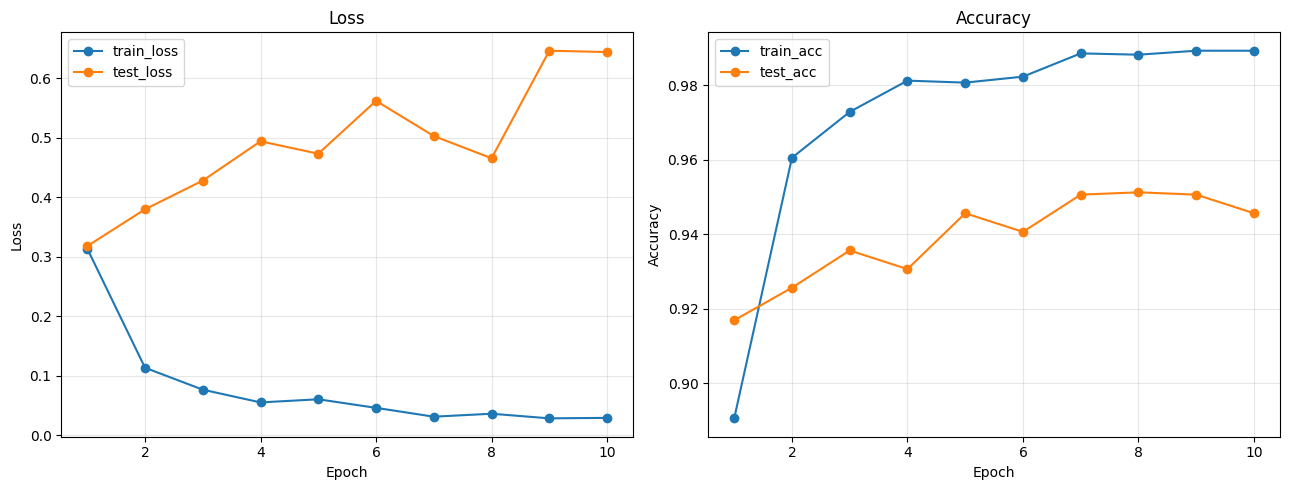

In [28]:
def plot_results(results: dict):
    epochs = range(1, len(results["train_loss"]) + 1)

    plt.figure(figsize=(13, 5))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, results["train_loss"], label="train_loss", marker="o")
    plt.plot(epochs, results["test_loss"], label="test_loss", marker="o")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.3)

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, results["train_acc"], label="train_acc", marker="o")
    plt.plot(epochs, results["test_acc"], label="test_acc", marker="o")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_results(results)

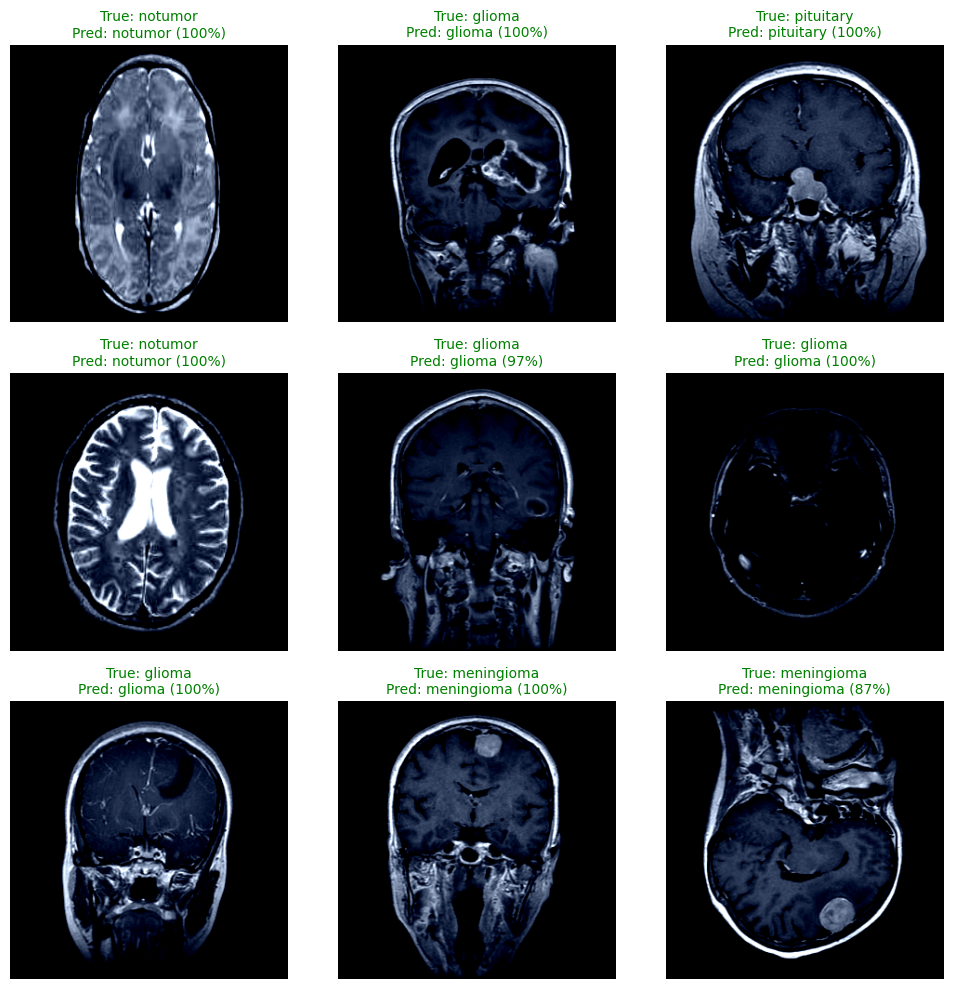

In [29]:
def plot_predictions(model, dataset, class_names, device, n=9):
    model.eval()

    cfg = timm.data.resolve_data_config({}, model=model)
    mean = torch.tensor(cfg["mean"]).view(3, 1, 1)
    std = torch.tensor(cfg["std"]).view(3, 1, 1)

    idxs = random.sample(range(len(dataset)), n)

    plt.figure(figsize=(10, 10))
    for i, idx in enumerate(idxs):
        img, label = dataset[idx]

        with torch.inference_mode():
            logits = model(img.unsqueeze(0).to(device))
            probs = torch.softmax(logits, dim=1)
            pred = probs.argmax(dim=1).item()
            conf = probs.max().item()

        img_show = (img.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

        plt.subplot(3, 3, i + 1)
        plt.imshow(img_show)
        plt.axis("off")
        color = "green" if pred == label else "red"
        plt.title(f"True: {class_names[label]}\nPred: {class_names[pred]} ({conf:.0%})",
                  color=color, fontsize=10)

    plt.tight_layout()
    plt.show()

class_names = test_dataloader.dataset.classes   
plot_predictions(model, test_dataloader.dataset, class_names, device)

In [33]:
model.eval().cpu()
dummy = torch.randn(32, 3, 299, 299)   
torch.onnx.export(model, dummy, "../models/best_model.onnx",
                  input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}},
                  opset_version=17)